Train skup: 2017-08-30 → 2025-05-12 (2813 dana)
Test skup:  2025-05-13 → 2025-06-01 (poslednjih 20 dana)

─── VALIDACIJA (Poslednjih 20 dana - BTC) ──────────────
      Date    Return  Realizovana_Vol  GARCH_Vol
2025-05-13  1.276762             1.30   2.797267
2025-05-14 -0.572410             1.33   2.747729
2025-05-15  0.247228             0.98   2.695013
2025-05-16 -0.279096             0.95   2.638663
2025-05-17 -0.354098             0.74   2.590231
2025-05-18  3.288406             1.58   2.547025
2025-05-19 -0.862267             1.64   2.639543
2025-05-20  1.181190             1.67   2.603558
2025-05-21  2.610574             1.78   2.568403
2025-05-22  1.897809             1.58   2.605606
2025-05-23 -3.922873             2.66   2.597189
2025-05-24  0.416905             2.59   2.783075
2025-05-25  1.169430             2.59   2.718986
2025-05-26  0.394324             2.30   2.672725
2025-05-27 -0.469430             2.04   2.618122
2025-05-28 -1.061519             0.87   2.574062
2025

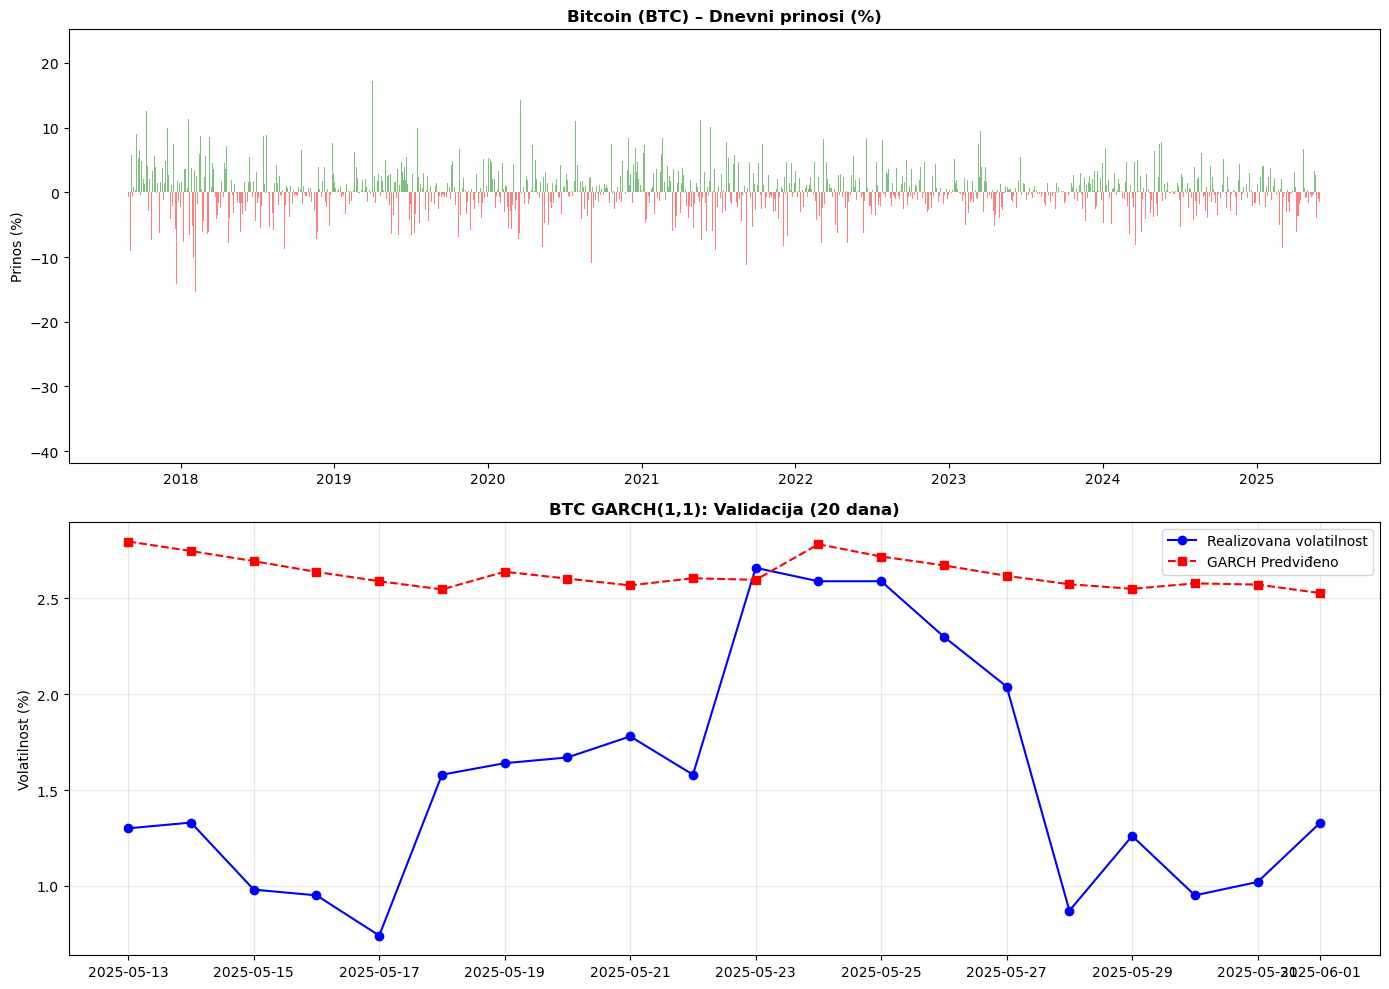


Model Summary (Bitcoin):
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -7464.12
Distribution:                  Normal   AIC:                           14936.2
Method:            Maximum Likelihood   BIC:                           14960.0
                                        No. Observations:                 2813
Date:                Sat, May 30 2026   Df Residuals:                     2812
Time:                        18:16:35   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1973  6.000e-02      

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from arch import arch_model

# ── UČITAVANJE PODATAKA ─────────────────────────────────────
# Putanja do tvog fajla za Bitcoin
df = pd.read_csv('/Users/tamaradrca/Podaci za diplomski/BTC_USD Binance Historical Data.csv') 
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Čišćenje cene (uklanjanje zareza ako postoje)
df['Price'] = df['Price'].astype(str).str.replace(',', '').astype(float)
df = df[['Date', 'Price']].dropna().drop_duplicates(subset=['Date'])

# Dnevni prinos u %
df['Return'] = 100 * df['Price'].pct_change()
df = df.dropna().reset_index(drop=True)

# ── 1. PODELA PODATAKA (POSLEDNJIH 20 DANA) ──────────────────
# Test set su poslednjih 20 dostupnih dana
test = df.tail(20).copy()

# Train set su svi podaci pre tih 20 dana
test_start_date = test['Date'].min()
train = df[df['Date'] < test_start_date].copy()

print(f"Train skup: {train['Date'].min().date()} → {train['Date'].max().date()} ({len(train)} dana)")
print(f"Test skup:  {test['Date'].min().date()} → {test['Date'].max().date()} (poslednjih {len(test)} dana)")

# ── 2. FIT GARCH(1,1) NA TRENING SETU ──────────────────────
# Koristimo p=1, q=1 jer je to standard koji profesor traži
model     = arch_model(train['Return'], vol='Garch', p=1, q=1, dist='normal')
model_fit = model.fit(disp='off')

# ── 3. ROLLING FORECAST ZA TEST SET (20 DANA) ──────────────
pred_vols = []
for i in range(len(test)):
    # Svaki dan dodajemo prethodni dan u trening da bi model "učio" u hodu
    cutoff = test['Date'].iloc[i - 1] if i > 0 else train['Date'].max()
    train_expanded = df[df['Date'] <= cutoff].copy()

    m  = arch_model(train_expanded['Return'], vol='Garch', p=1, q=1, dist='normal')
    mf = m.fit(disp='off')
    fc = mf.forecast(horizon=1)
    
    # Izvlačimo predviđenu standardnu devijaciju (koren iz varijanse)
    vol = np.sqrt(fc.variance.values[-1, 0])
    pred_vols.append(vol)

test['GARCH_Vol'] = pred_vols
stvarne_btc = [1.30,1.33,0.98,0.95,0.74,1.58,1.64,1.67,1.78,1.58,
               2.66,2.59,2.59,2.30,2.04,0.87,1.26,0.95,1.02,1.33]
test['Realizovana_Vol'] = stvarne_btc

print("\n─── VALIDACIJA (Poslednjih 20 dana - BTC) ──────────────")
print(test[['Date', 'Return', 'Realizovana_Vol', 'GARCH_Vol']].to_string(index=False))



# ── 5. VIZUALIZACIJA ────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Graf 1: Dnevni prinosi BTC (vidi se velika oscilacija)
axes[0].bar(df['Date'], df['Return'], 
            color=['green' if r > 0 else 'red' for r in df['Return']], alpha=0.5)
axes[0].set_title('Bitcoin (BTC) – Dnevni prinosi (%)', fontweight='bold')
axes[0].set_ylabel('Prinos (%)')

# Graf 2: Validacija 20 dana + 7 dana prognoze
future_dates = pd.date_range(start=df['Date'].max() + pd.Timedelta(days=1), periods=7, freq='D')

axes[1].plot(test['Date'], test['Realizovana_Vol'], marker='o', label='Realizovana volatilnost', color='blue')
axes[1].plot(test['Date'], test['GARCH_Vol'], marker='s', linestyle='--', label='GARCH Predviđeno', color='red')


axes[1].set_title('BTC GARCH(1,1): Validacija (20 dana)', fontweight='bold')
axes[1].set_ylabel('Volatilnost (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Snimanje datuma ako ti trebaju za MLP kod za Bitcoin
test[['Date']].to_csv('btc_garch_dates.csv', index=False)
print("\nModel Summary (Bitcoin):")
print(model_fit.summary())